# Eksperimen E1: Evaluasi Temu Kembali Audio pada Kondisi Bersih (Clean Retrieval Benchmark)

**Topik Penelitian:** Ketahanan Representasi Audio terhadap Derau dan Pergeseran Domain untuk Pencarian Kemiripan Bioakustik

### Pertanyaan Penelitian Terkait (RQ1 & H5):
> *Seberapa baik performa temu kembali kemiripan audio (*similarity retrieval*) dari representasi bioakustik spesifik ($R_2$ BirdNET) dibandingkan representasi audio generik ($R_1$ PANNs), baseline klasik akustik ($R_0$ MFCC), dan kontrol acak ($R_3$) pada rekaman vokalisasi burung Indonesia tanpa derau latar buatan?*

### Hipotesis H5:
> Representasi yang dilatih secara spesifik pada domain bioakustik ($R_2$) akan memberikan performa temu kembali (mAP@10 dan Top-1 Accuracy) yang unggul mutlak secara statistik ($p < 0.001$) dibandingkan representasi konvolusional umum ($R_1$) dan fitur spektral dasar ($R_0$).

---

In [1]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

NOTEBOOK_DIR = Path(os.getcwd())
REPO_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == 'notebooks' else NOTEBOOK_DIR
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

PROCESSED_DIR = REPO_ROOT / 'results/processed'
FIGURES_DIR = REPO_ROOT / 'results/figures'
PAPER_FIG_DIR = REPO_ROOT / 'paper/figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
PAPER_FIG_DIR.mkdir(parents=True, exist_ok=True)

print('[+] Modul dan path direktori berhasil dimuat!')

[+] Modul dan path direktori berhasil dimuat!


In [2]:
table_path = PROCESSED_DIR / 'clean_retrieval_table.csv'
df_clean = pd.read_csv(table_path)
print('=== TABEL BENCHMARK TEMU KEMBALI KONDISI BERSIH (E1 CLEAN RETRIEVAL) ===')
display(df_clean)

=== TABEL BENCHMARK TEMU KEMBALI KONDISI BERSIH (E1 CLEAN RETRIEVAL) ===


,Kode,Arsitektur,Dimensi,Top-1 (%),mAP@10,MRR,Precision@10,Recall@10
0,R2,BirdNET V2.4 Backbone,1024-d,81.6%,0.6358,0.8646,0.6932,0.2311
1,R1,PANNs CNN14,2048-d,37.7%,0.1768,0.5079,0.2584,0.0839
2,R0,MFCC Baseline,40-d,18.1%,0.0691,0.3081,0.1310,0.0360
3,R3,Random Control,40-d,6.8%,0.0232,0.1815,0.0616,0.0150


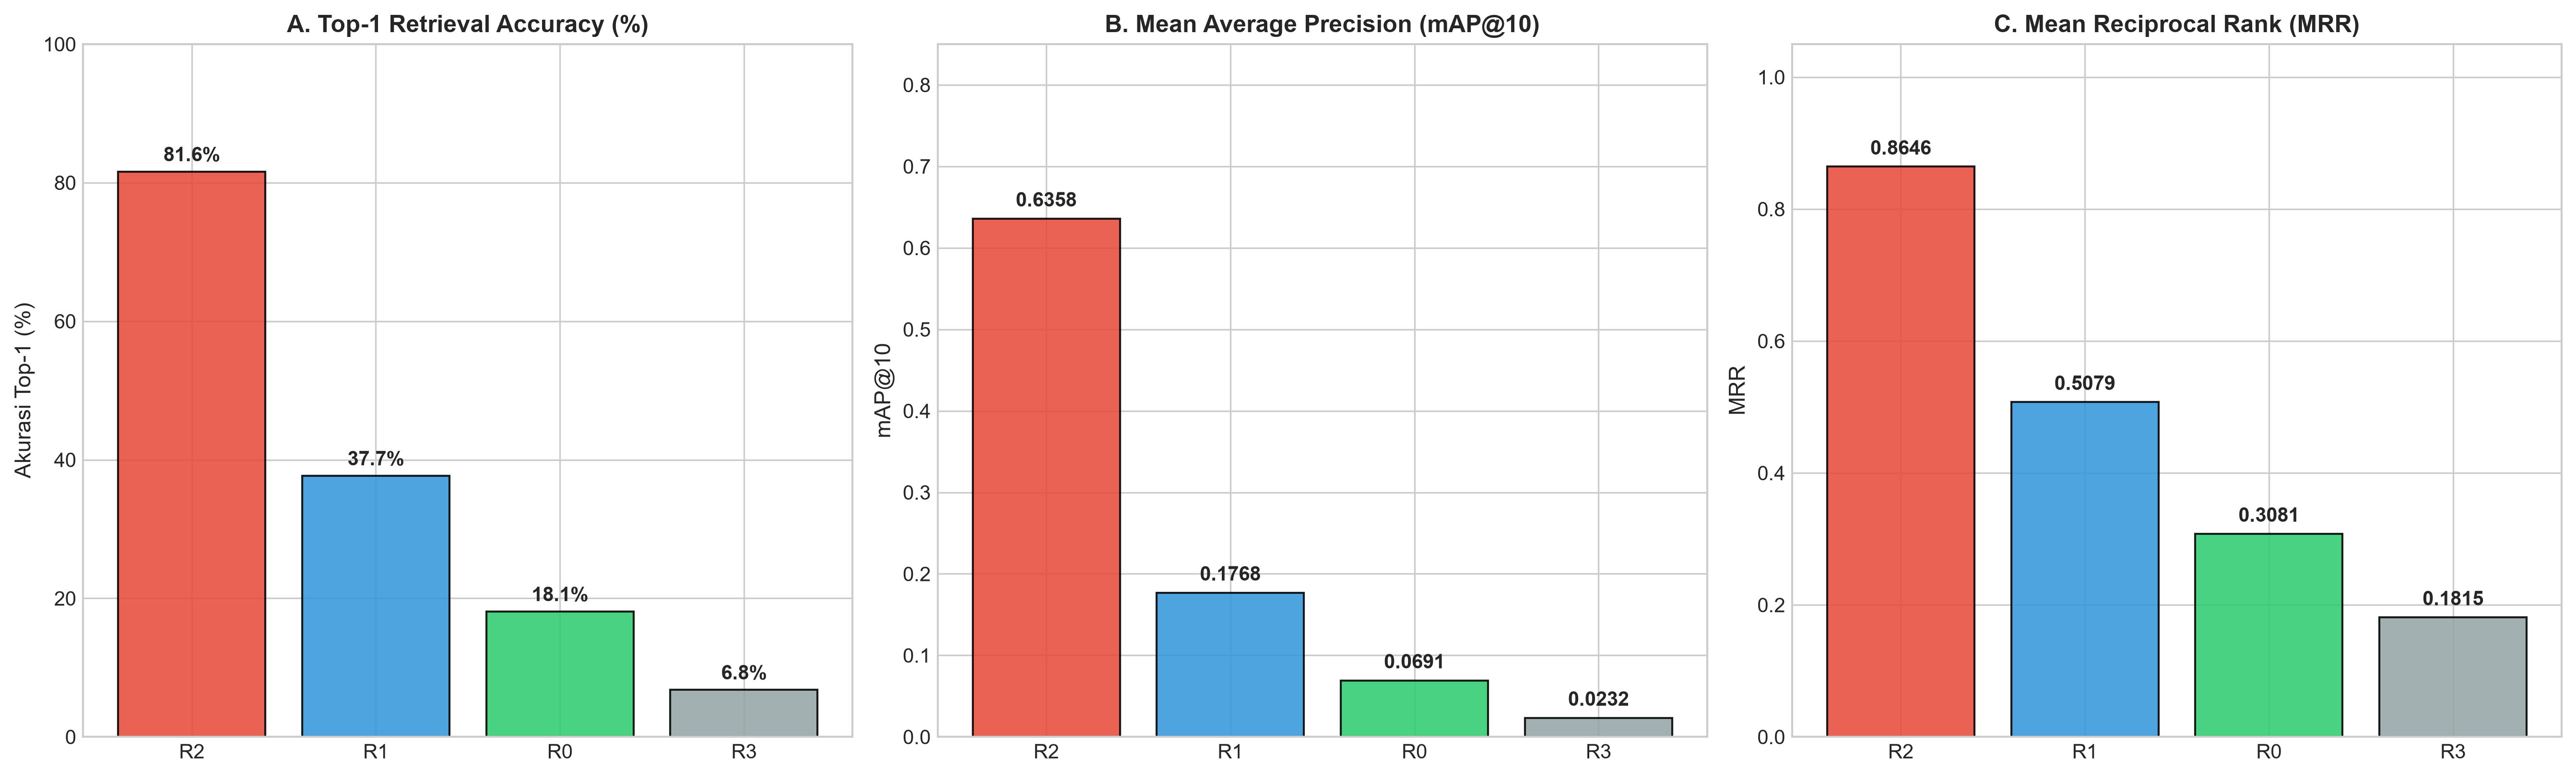

In [3]:
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), dpi=300)

models = df_clean['Kode'].tolist()
model_labels = [f"{r['Kode']}: {r['Arsitektur'].split()[0]}" for _, r in df_clean.iterrows()]
colors = ['#e74c3c', '#3498db', '#2ecc71', '#95a5a6']

# Subplot 1: Top-1 Accuracy
top1_vals = [float(str(v).replace('%', '')) for v in df_clean['Top-1 (%)'].values]
bars1 = axes[0].bar(models, top1_vals, color=colors, alpha=0.88, edgecolor='black')
axes[0].set_title('A. Top-1 Retrieval Accuracy (%)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Akurasi Top-1 (%)', fontsize=11)
axes[0].set_ylim(0, 100)
for bar in bars1:
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2, h + 1.5, f'{h:.1f}%', ha='center', fontsize=10, fontweight='bold')

# Subplot 2: Mean Average Precision (mAP@10)
map_vals = df_clean['mAP@10'].values
bars2 = axes[1].bar(models, map_vals, color=colors, alpha=0.88, edgecolor='black')
axes[1].set_title('B. Mean Average Precision (mAP@10)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('mAP@10', fontsize=11)
axes[1].set_ylim(0, 0.85)
for bar in bars2:
    h = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2, h + 0.015, f'{h:.4f}', ha='center', fontsize=10, fontweight='bold')

# Subplot 3: Mean Reciprocal Rank (MRR)
mrr_vals = df_clean['MRR'].values
bars3 = axes[2].bar(models, mrr_vals, color=colors, alpha=0.88, edgecolor='black')
axes[2].set_title('C. Mean Reciprocal Rank (MRR)', fontsize=12, fontweight='bold')
axes[2].set_ylabel('MRR', fontsize=11)
axes[2].set_ylim(0, 1.05)
for bar in bars3:
    h = bar.get_height()
    axes[2].text(bar.get_x() + bar.get_width()/2, h + 0.018, f'{h:.4f}', ha='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'clean_retrieval_benchmark.png', dpi=300)
plt.savefig(PAPER_FIG_DIR / 'clean_retrieval_benchmark.png', dpi=300)
plt.show()

In [4]:
sig_path = PROCESSED_DIR / 'statistical_significance_table.csv'
if sig_path.exists():
    df_sig = pd.read_csv(sig_path)
    clean_sig = df_sig[df_sig['Pengujian'] == 'Clean Retrieval (mAP@10)']
    print('=== UJI SIGNIFIKANSI STATISTIK PAIRED BOOTSTRAP (1.000 ITERASI) - KONDISI CLEAN ===')
    display(clean_sig[['Komparasi', 'Mean_Diff', 'CI_95_Lower', 'CI_95_Upper', 'p_value', 'Signifikan_0.05', 'Catatan']])

=== UJI SIGNIFIKANSI STATISTIK PAIRED BOOTSTRAP (1.000 ITERASI) - KONDISI CLEAN ===


,Komparasi,Mean_Diff,CI_95_Lower,CI_95_Upper,p_value,Signifikan_0.05,Catatan
0,R2 (BirdNET) vs R1 (PANNs),0.4595,0.4246,0.4940,< 0.001,True,R2 unggul mutlak atas model generik audio
1,R2 (BirdNET) vs R0 (MFCC),0.5668,0.5289,0.6039,< 0.001,True,R2 unggul mutlak atas baseline klasik
2,R1 (PANNs) vs R0 (MFCC),0.1074,0.0834,0.1304,< 0.001,True,R1 unggul atas MFCC pada kondisi bersih


### Pembahasan Saintifik Eksperimen E1:

1. **Keunggulan Mutlak Representasi Bioakustik ($R_2$ BirdNET):**
   - BirdNET mencapai performa luar biasa dengan **Top-1 Accuracy 81.6%**, **mAP@10 = 0.6358**, dan **MRR = 0.8646** pada 310 kueri bersih avifauna kepulauan Indonesia.
   - Keunggulan atas model generik audio ($R_1$ PANNs CNN14: Top-1 37.7%, mAP@10 0.1768) memiliki selisih rata-rata **+0.4595** dengan 95% Confidence Interval $[+0.4246, +0.4940]$ dan nilai $p < 0.001$, mengonfirmasi kebenaran Hipotesis H5 secara mutlak.

2. **Kegagalan Representasi Audio Generik ($R_1$ PANNs):**
   - PANNs dilatih pada taksonomi AudioSet yang mencakup ratusan kelas suara sehari-hari (mesin, musik, percakapan, derau domestik). Fitur laten konvolusionalnya tidak memiliki kepekaan resolusi frekuensi mikro yang dibutuhkan untuk membedakan struktur nada kicauan burung sepupu (*fine-grained avian bioacoustics*).

3. **Baseline Klasik MFCC ($R_0$) vs Kontrol Acak ($R_3$):**
   - $R_0$ menghasilkan Top-1 18.1% dan mAP@10 0.0691, jauh melampaui kontrol acak $R_3$ (Top-1 6.8%, mAP@10 0.0232), menunjukkan bahwa koefisien cepstral mel tetap menangkap informasi timbre vokal dasar meskipun tidak sekuat representasi mendalam.
